# What a home kitchen segment contains

This notebook is the EPIC-KITCHENS-100 half of the project. The question is which parts of a usable training clip are already present when one person records at home. A usable clip lets someone who was not there tell the task, when it started and ended, and what happened.

Each row of the public annotation tables is one action segment. The counts below are computed from those tables. The videos themselves are not loaded. The DROID comparison is the next stage: the lab side of the component table will be coded from the published episode specification, then checked against the language annotations and the success and failure split. Ego4D stays optional.

The loading and the counts live in `src/epic.py`. This notebook calls that module and reads what it returns.


## 1. Load and preprocess

`load_segments` does six things.

1. It reads the train file, the validation file, and the test timestamp file, and stacks them with a `split` column.
2. It parses each `HH:MM:SS` timestamp into seconds. A missing narration timestamp stays missing.
3. It sets `duration_s` to the stop time minus the start time. That clock difference is the action length used in the rest of this notebook.
4. It joins `EPIC_100_video_info.csv`, so every segment carries that video's duration, listed frame rate, and resolution.
5. It maps `verb_class` and `noun_class` to the class names in the published class tables. The raw `verb` and `noun` strings stay on the row. Many of those strings share one class.
6. It sets `labels_in_file` to false on the test split. That file has no narration, verb, or noun column. An empty label there means the column was not released. It does not mean a participant left a note blank.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "epic.py").is_file():
    raise FileNotFoundError(
        "Run this notebook from the project root, the folder that contains src/ and data/."
    )
sys.path.insert(0, str(ROOT))

from src.epic import (
    class_concentration,
    class_frequencies,
    collection_counts,
    coverage,
    duration_summary,
    frame_clock_report,
    load_segments,
    participant_overlap,
    participant_summary,
    recording_formats,
    recording_length,
)

segments = load_segments()
print(f"{len(segments):,} segments, {segments['participant_id'].nunique()} participants, {segments['video_id'].nunique()} videos")


89,977 segments, 37 participants, 700 videos


In [2]:
preview_columns = [
    "split",
    "participant_id",
    "video_id",
    "start_s",
    "stop_s",
    "duration_s",
    "narration",
    "verb",
    "verb_name",
    "noun_name",
]
print("Train rows include the narration, the raw verb, and the verb class.")
display(segments.loc[segments["split"] == "train", preview_columns].head(3))
print("Test rows have timing only. The label cells are empty because those columns are not in the test file.")
display(segments.loc[~segments["labels_in_file"], preview_columns].head(2))


Train rows include the narration, the raw verb, and the verb class.


,split,participant_id,video_id,start_s,stop_s,duration_s,narration,verb,verb_name,noun_name
0,train,P01,P01_01,0.14,3.37,3.23,open door,open,open,cupboard
1,train,P01,P01_01,4.37,6.17,1.8,turn on light,turn-on,turn-on,light
2,train,P01,P01_01,24.97,26.2,1.23,open drawer,open,open,drawer


Test rows have timing only. The label cells are empty because those columns are not in the test file.


,split,participant_id,video_id,start_s,stop_s,duration_s,narration,verb,verb_name,noun_name
76885,test,P01,P01_101,2.86,3.87,1.01,<NA>,<NA>,<NA>,<NA>
76886,test,P01,P01_101,4.97,5.75,0.78,<NA>,<NA>,<NA>,<NA>


## 2. Do the files match the proposal?

The proposal says the release contains 100 hours, 700 videos, 89,977 action segments, and 37 participants. The participant counts on the separate splits will not add to 37. The same person can appear in more than one split, and the `all` row counts people once.

The hour count needs the same care. Summing the video durations and summing the segment durations answer different questions. The segments do not cover every moment of every video.


In [3]:
counts = collection_counts(segments)
length = recording_length(segments)
overlap = participant_overlap(segments)
people = participant_summary(segments)

display(counts)
display(length.round(2))
display(overlap)
display(people.round(3))

hours = length.iloc[0]
person = people.iloc[0]
print(
    f"The {int(hours.videos)} videos last {hours.video_hours:.2f} hours. "
    f"The annotated segments last {hours.segment_hours:.2f} hours. "
    f"The proposal's 100 hours is the video total."
)
print(
    f"Segments per participant run from {int(person.min_segments):,} to {int(person.max_segments):,}, "
    f"with a median of {person.median_segments:.0f}. "
    f"{person.largest_participant} contributes {person.largest_share:.1%} of segments, "
    f"and the five largest contributors account for {person.top5_share:.1%}."
)


,split,participants,videos,segments
0,train,32,495,67217
1,validation,32,138,9668
2,test,20,67,13092
3,all,37,700,89977


,videos,video_hours,segment_hours
0,700,100.03,77.83


,splits,participants
0,1,6
1,2,15
2,3,16


,participants,min_segments,median_segments,max_segments,largest_participant,largest_share,top5_share
0,37,116,1804.0,11477,P22,0.128,0.465


The 700 videos last 100.03 hours. The annotated segments last 77.83 hours. The proposal's 100 hours is the video total.
Segments per participant run from 116 to 11,477, with a median of 1804. P22 contributes 12.8% of segments, and the five largest contributors account for 46.5%.


## 3. How often is each field filled in?

Coverage is the share of segments with a non-empty value. On the test split, narration, verb, and noun are reported as not in the file. Giving those cells a rate of zero would treat a withheld column as a blank note.


In [4]:
def format_coverage(table: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for record in table.to_dict(orient="records"):
        if not record["in_file"]:
            present = missing = share = "not in file"
        else:
            present = f"{int(record['present']):,}"
            missing = f"{int(record['missing']):,}"
            share = f"{record['share_present']:.1%}"
        rows.append(
            {
                "field": record["field"],
                "split": record["split"],
                "segments": f"{int(record['segments']):,}",
                "present": present,
                "missing": missing,
                "share present": share,
            }
        )
    return pd.DataFrame(rows)

held = coverage(segments)
display(format_coverage(held))

narration_time = held[(held["field"] == "narration timestamp") & (held["split"] == "all")].iloc[0]
print(
    "Start and stop timestamps are present on every segment. "
    "On train and validation, the narration, the verb, and the noun are present on every row. "
    f"The narration timestamp is missing on {int(narration_time.missing):,} of {int(narration_time.segments):,} segments."
)


,field,split,segments,present,missing,share present
0,start timestamp,train,"67,217","67,217",0,100.0%
1,start timestamp,validation,"9,668","9,668",0,100.0%
2,start timestamp,test,"13,092","13,092",0,100.0%
3,start timestamp,all,"89,977","89,977",0,100.0%
4,stop timestamp,train,"67,217","67,217",0,100.0%
5,stop timestamp,validation,"9,668","9,668",0,100.0%
6,stop timestamp,test,"13,092","13,092",0,100.0%
7,stop timestamp,all,"89,977","89,977",0,100.0%
8,narration timestamp,train,"67,217","67,100",117,99.8%
9,narration timestamp,validation,"9,668","9,598",70,99.3%


Start and stop timestamps are present on every segment. On train and validation, the narration, the verb, and the noun are present on every row. The narration timestamp is missing on 187 of 89,977 segments.


## 4. How long is an action?

Length is the published stop time minus the published start time. The histogram shows the body of the distribution, up to 30 seconds. The table keeps the tail, including the longest segment.


,split,segments,nonpositive,min_s,p05_s,median_s,mean_s,p95_s,max_s,longer_than_60s
0,train,67217,0,0.20,0.57,1.57,3.12,10.52,297.15,59
1,validation,9668,0,0.50,0.74,1.96,3.68,11.92,146.98,15
2,test,13092,0,0.10,0.51,1.36,2.67,9.38,208.65,9
3,all,89977,0,0.10,0.57,1.57,3.11,10.55,297.15,83


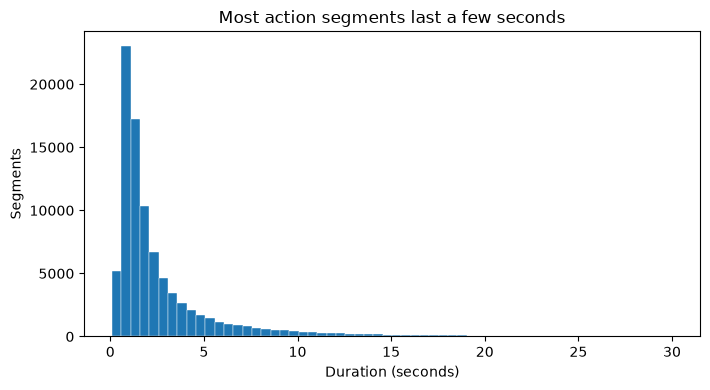

497 segments (0.6% of the release) are longer than 30 seconds and are left off the histogram. The longest lasts 297 seconds. No segment has a duration of zero or less.


In [5]:
def format_duration(table: pd.DataFrame) -> pd.DataFrame:
    shown = table.copy()
    for column in shown.columns:
        if column.endswith("_s"):
            shown[column] = shown[column].map(lambda value: f"{value:.2f}")
    return shown

display(format_duration(duration_summary(segments)))

shown = segments.loc[segments["duration_s"] <= 30, "duration_s"]
omitted = int((segments["duration_s"] > 30).sum())

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.hist(shown, bins=60, color="C0", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Duration (seconds)")
ax.set_ylabel("Segments")
ax.set_title("Most action segments last a few seconds")
fig.tight_layout()
plt.show()

print(
    f"{omitted:,} segments ({omitted / len(segments):.1%} of the release) are longer than 30 seconds "
    f"and are left off the histogram. The longest lasts {segments['duration_s'].max():.0f} seconds. "
    f"No segment has a duration of zero or less."
)


## 5. Which actions are common?

The release publishes 97 verb classes and 300 noun classes. A class gathers many raw strings from the narrations. Train alone uses 856 raw verb strings and all 97 verb classes. Counting the raw strings would treat those strings as different actions, so the frequencies below count classes.

The test split is left out. It has no verb or noun column.


In [6]:
def format_concentration(table: pd.DataFrame) -> pd.DataFrame:
    shown = table.copy()
    for column in ("top_share", "top10_share"):
        shown[column] = shown[column].map(lambda value: f"{value:.1%}")
    return shown

verbs = class_concentration(segments, "verb")
nouns = class_concentration(segments, "noun")
display(format_concentration(verbs))
display(format_concentration(nouns))

verb_train, verb_val = verbs.iloc[0], verbs.iloc[1]
noun_train, noun_val = nouns.iloc[0], nouns.iloc[1]
print(
    f"The most common verb class is {verb_train.top_class} on train ({verb_train.top_share:.1%}) "
    f"and {verb_val.top_class} on validation ({verb_val.top_share:.1%}). "
    f"The ten most common verb classes cover {verb_train.top10_share:.1%} of train "
    f"and {verb_val.top10_share:.1%} of validation."
)
print(
    f"The most common noun class is {noun_train.top_class} on train ({noun_train.top_share:.1%}) "
    f"and {noun_val.top_class} on validation ({noun_val.top_share:.1%}). "
    f"The ten most common noun classes cover {noun_train.top10_share:.1%} of train "
    f"and {noun_val.top10_share:.1%} of validation."
)


,split,segments,classes_used,raw_strings,top_class,top_share,top10_share
0,train,67217,97,856,take,22.1%,78.7%
1,validation,9668,78,333,take,20.0%,81.1%
2,train+validation,76885,97,902,take,21.8%,78.9%


,split,segments,classes_used,raw_strings,top_class,top_share,top10_share
0,train,67217,289,2032,tap,5.4%,32.3%
1,validation,9668,211,668,plate,4.4%,32.7%
2,train+validation,76885,293,2214,tap,5.2%,32.2%


The most common verb class is take on train (22.1%) and take on validation (20.0%). The ten most common verb classes cover 78.7% of train and 81.1% of validation.
The most common noun class is tap on train (5.4%) and plate on validation (4.4%). The ten most common noun classes cover 32.3% of train and 32.7% of validation.


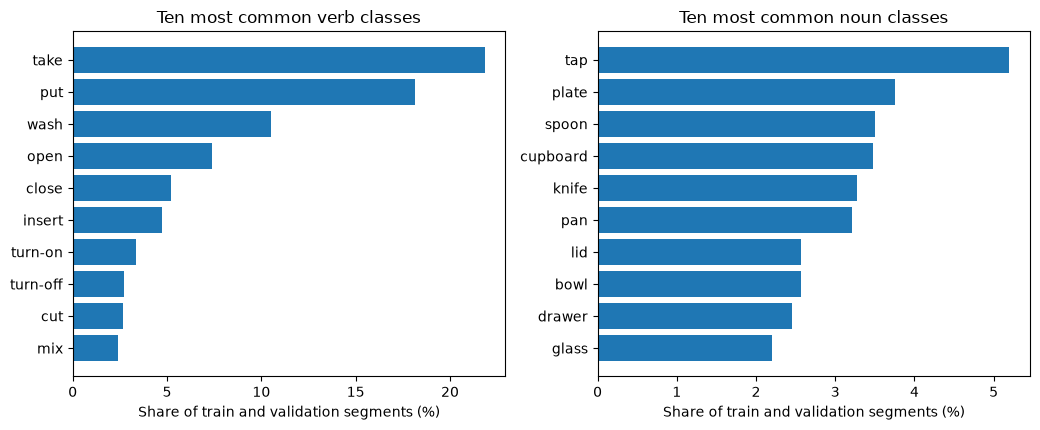

In [7]:
def shares_as_percent(table: pd.DataFrame) -> pd.DataFrame:
    shown = table.copy()
    shown["share"] = shown["share"] * 100
    return shown

verb_freq = shares_as_percent(class_frequencies(segments, "verb", n=10))
noun_freq = shares_as_percent(class_frequencies(segments, "noun", n=10))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for ax, freq, title in (
    (axes[0], verb_freq, "Ten most common verb classes"),
    (axes[1], noun_freq, "Ten most common noun classes"),
):
    plotted = freq.iloc[::-1]
    ax.barh(plotted["class_name"], plotted["share"], color="C0")
    ax.set_xlabel("Share of train and validation segments (%)")
    ax.set_title(title)
fig.tight_layout()
plt.show()


## 6. What these tables can say about the recording

The segment tables do not have a kitchen id, an audio column, or a camera model. The proposal's count of 45 kitchens, and the statement that the camera was a head-mounted GoPro with audio, come from the collection paper. They are not totals we can recompute here.

`EPIC_100_video_info.csv` does list a frame rate and a resolution for every video. That is the sensor information in these files.


In [8]:
fps, resolution = recording_formats(segments)
display(fps)
display(resolution)

common = int(fps.loc[fps["fps"].isin([50.00, 59.94]), "videos"].sum())
hd = int(resolution.loc[resolution["resolution"] == "1920x1080", "videos"].iloc[0])
print(f"{common} of {int(fps['videos'].sum())} videos are listed at 50 or 59.94 fps.")
print(f"{hd} of {int(resolution['videos'].sum())} videos are 1920x1080.")


,fps,videos
0,59.94,423
1,50.00,268
2,29.97,4
3,47.95,4
4,90.00,1


,resolution,videos
0,1920x1080,694
1,1280x720,4
2,1920x1440,2


691 of 700 videos are listed at 50 or 59.94 fps.
694 of 700 videos are 1920x1080.


## 7. Do the frame numbers agree with the clock?

This is a check on the timestamps, not a second way to measure length. For each segment we divide the frame span by the listed frame rate and compare that with `duration_s`. A video is counted as agreeing when the median of that ratio is between 0.9 and 1.1. Videos outside the band are listed rather than rescaled. The durations above stay on the timestamps.


In [9]:
summary, exceptions = frame_clock_report(segments)
shown_summary = summary.copy()
shown_summary["max_abs_seconds"] = shown_summary["max_abs_seconds"].map(lambda value: f"{value:.3f}")
display(shown_summary)
display(exceptions)

gap = float(summary["max_abs_seconds"].iloc[0])
outside = int(summary["videos_outside"].iloc[0])
print(
    f"On {int(summary['videos_near_one'].iloc[0])} videos, the frame span and the clock differ by at most {gap:.3f} seconds."
)
print(
    f"The other {outside} videos contain {int(summary['segments_outside'].iloc[0]):,} segments. "
    "The ratio column is frame-span duration divided by timestamp duration."
)

uncommon_rates = set(fps.loc[~fps["fps"].isin([50.00, 59.94]), "fps"].round(2))
exception_rates = set(exceptions["listed_fps"].round(2))
print(
    "The listed rates on those videos are "
    + ", ".join(f"{rate:.2f}" for rate in sorted(exception_rates))
    + "."
)
print(f"Those are the listed rates other than 50 and 59.94: {uncommon_rates == exception_rates}.")


,videos_near_one,segments_in_those_videos,max_abs_seconds,videos_outside,segments_outside
0,691,89242,0.152,9,735


,video_id,listed_fps,segments,median_ratio
0,P09_07,29.97,17,2.002
1,P09_08,29.97,27,2.002
2,P10_04,29.97,506,2.002
3,P17_01,47.95,16,1.251
4,P17_02,47.95,27,1.251
5,P17_03,47.95,28,1.251
6,P17_04,47.95,45,1.251
7,P18_02,29.97,27,2.002
8,P18_09,90.00,42,0.667


On 691 videos, the frame span and the clock differ by at most 0.152 seconds.
The other 9 videos contain 735 segments. The ratio column is frame-span duration divided by timestamp duration.
The listed rates on those videos are 29.97, 47.95, 90.00.
Those are the listed rates other than 50 and 59.94: True.


## 8. Preliminary findings

The tables above support five findings.

The load matches the proposal on the quantities these files contain. There are 37 participants, 700 videos, and 89,977 segments. The videos total 100.03 hours. The annotated actions total 77.83 hours, so the proposal's "100 hours" should stay attached to the videos.

Every segment has a start and a stop, and none of those intervals is empty. The median action lasts 1.57 seconds. The distribution is skewed: 83 segments are longer than a minute, and the longest lasts 297 seconds.

Where the labels were released, the narration, the verb, and the noun are filled in on every row. The narration timestamp is the note with gaps: 117 segments in train and 70 in validation. The test file cannot be used for the narration, verb, or noun rates, because those columns are not in it.

The actions are uneven. The verb class `take` is about a fifth of train and of validation, and the ten most common verb classes cover about four fifths of each labeled split. Noun classes are less concentrated. The leading noun class is `tap` on train and `plate` on validation, and the ten most common noun classes cover about a third of each labeled split.

The segments are also uneven across people. Six participants appear in only one split, fifteen in two, and sixteen in all three, which is why the split counts of people do not add to 37. Five participants account for 46.5% of segments. A rate computed on the whole release describes some participants much more heavily than others.

## 9. Is the plan feasible?

The home-recording side of the component table can be filled from these files for a narration, a verb, a noun, and a start and an end, and the completeness of each of those fields is measurable. The same pass should keep the two limits above. Label coverage is a train-and-validation number. The 45 kitchens named in the proposal are not a column in these tables, and neither is audio, so both stay cited to the collection paper.

The lab side is still open, and it does not require the robot video. The plan is to code DROID's published episode specification into the same component list and check it against the language-annotation file and the success and failure split. This notebook does not do that check. Ego4D remains optional; the comparison does not depend on it.

## Re-running this notebook

From the project root, install `requirements.txt`, then open `analysis.ipynb`. The kernel's working directory needs to be the project root, the folder that contains `src/` and `data/`. The annotation tables are already in `data/epic/`. They come from [epic-kitchens/epic-kitchens-100-annotations](https://github.com/epic-kitchens/epic-kitchens-100-annotations).
